In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

train_df = pd.read_csv("/content/UNSW_NB15_training-set.csv")
test_df = pd.read_csv("/content/UNSW_NB15_testing-set.csv")

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

Training shape: (175341, 45)
Testing shape: (82332, 45)


In [5]:
train_df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,175341.0,8.767100e+04,5.061673e+04,1.0,43836.000000,87671.000000,1.315060e+05,1.753410e+05
dur,175341.0,1.359389e+00,6.480249e+00,0.0,0.000008,0.001582,6.680690e-01,5.999999e+01
spkts,175341.0,2.029866e+01,1.368876e+02,1.0,2.000000,2.000000,1.200000e+01,9.616000e+03
dpkts,175341.0,1.896959e+01,1.102583e+02,0.0,0.000000,2.000000,1.000000e+01,1.097400e+04
sbytes,175341.0,8.844844e+03,1.747656e+05,28.0,114.000000,430.000000,1.418000e+03,1.296523e+07
dbytes,175341.0,1.492892e+04,1.436542e+05,0.0,0.000000,164.000000,1.102000e+03,1.465555e+07
rate,175341.0,9.540619e+04,1.654010e+05,0.0,32.786140,3225.806520,1.250000e+05,1.000000e+06
sttl,175341.0,1.795470e+02,1.029400e+02,0.0,62.000000,254.000000,2.540000e+02,2.550000e+02
dttl,175341.0,7.960957e+01,1.105069e+02,0.0,0.000000,29.000000,2.520000e+02,2.540000e+02
sload,175341.0,7.345403e+07,1.883574e+08,0.0,13053.338870,879674.750000,8.888889e+07,5.988000e+09


In [6]:
print(train_df["label"].value_counts())
print("\nPercentages:")
print((train_df["label"].value_counts(normalize=True) * 100).round(2))

print("\nAttack categories:")
print(train_df["attack_cat"].value_counts())

label
1    119341
0     56000
Name: count, dtype: int64

Percentages:
label
1    68.06
0    31.94
Name: proportion, dtype: float64

Attack categories:
attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


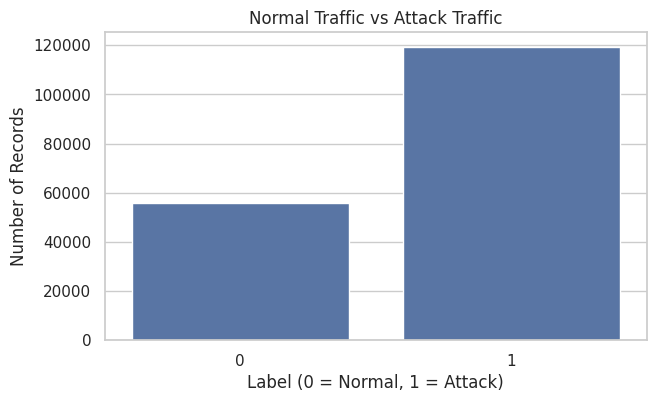

In [7]:
plt.figure(figsize=(7, 4))
sns.countplot(data=train_df, x="label")
plt.title("Normal Traffic vs Attack Traffic")
plt.xlabel("Label (0 = Normal, 1 = Attack)")
plt.ylabel("Number of Records")
plt.show()

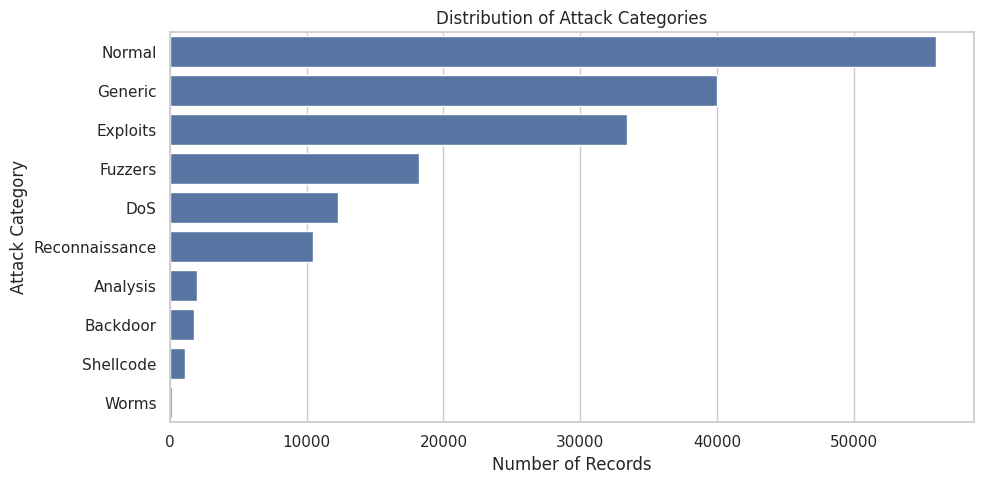

In [8]:
plt.figure(figsize=(10, 5))
order = train_df["attack_cat"].value_counts().index
sns.countplot(
    data=train_df,
    y="attack_cat",
    order=order
)
plt.title("Distribution of Attack Categories")
plt.xlabel("Number of Records")
plt.ylabel("Attack Category")
plt.tight_layout()
plt.show()

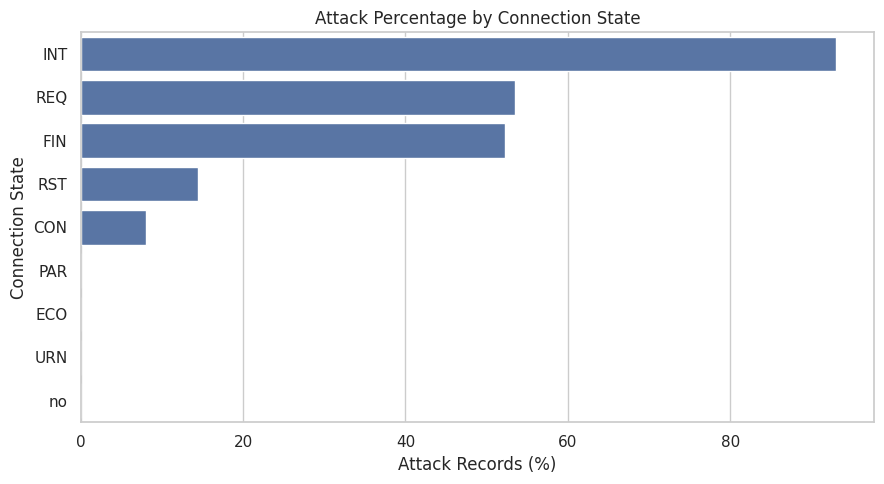

state
INT    93.05
REQ    53.54
FIN    52.23
RST    14.46
CON     8.01
PAR     0.00
ECO     0.00
URN     0.00
no      0.00
Name: label, dtype: float64


In [9]:
state_attack = (
    train_df.groupby("state")["label"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(
    x=state_attack.values,
    y=state_attack.index
)
plt.title("Attack Percentage by Connection State")
plt.xlabel("Attack Records (%)")
plt.ylabel("Connection State")
plt.tight_layout()
plt.show()

print(state_attack.round(2))

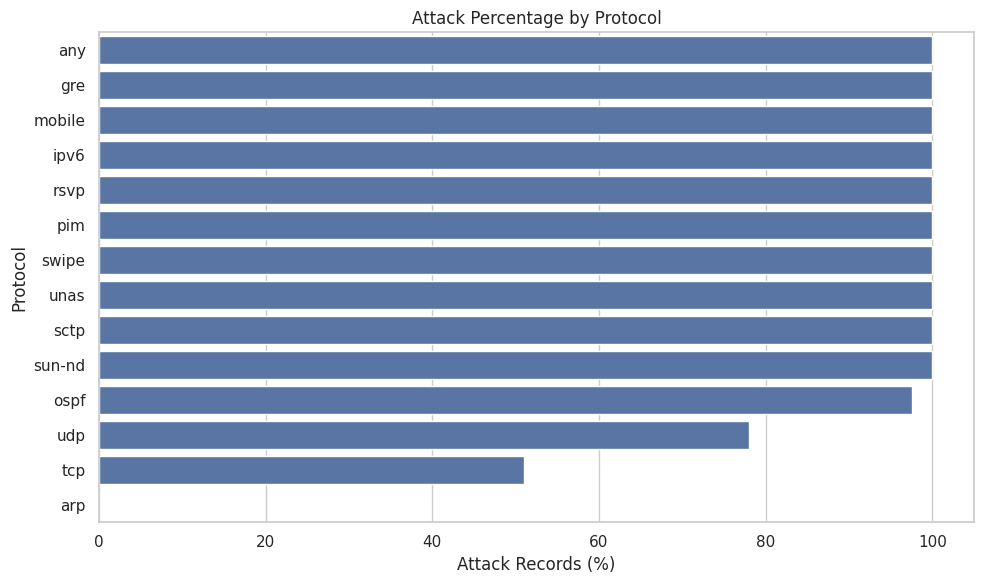

In [10]:
protocol_stats = (
    train_df.groupby("proto")["label"]
    .agg(["count", "mean"])
)

protocol_stats["attack_pct"] = protocol_stats["mean"] * 100

# Focus on protocols with at least 200 records
common_protocols = protocol_stats[
    protocol_stats["count"] >= 200
].sort_values("attack_pct", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=common_protocols.reset_index(),
    x="attack_pct",
    y="proto"
)
plt.title("Attack Percentage by Protocol")
plt.xlabel("Attack Records (%)")
plt.ylabel("Protocol")
plt.tight_layout()
plt.show()

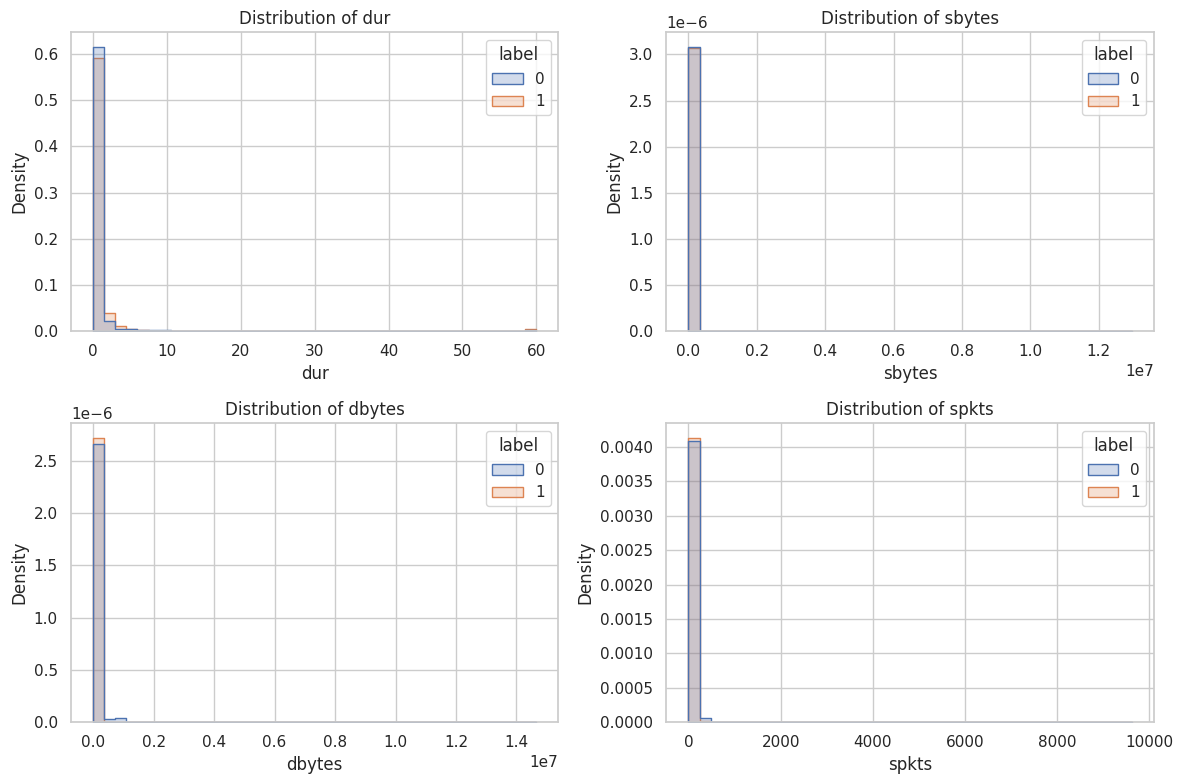

In [11]:
features = ["dur", "sbytes", "dbytes", "spkts"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, ax in zip(features, axes.flatten()):
    sns.histplot(
        data=train_df,
        x=col,
        hue="label",
        bins=40,
        element="step",
        stat="density",
        common_norm=False,
        ax=ax
    )
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

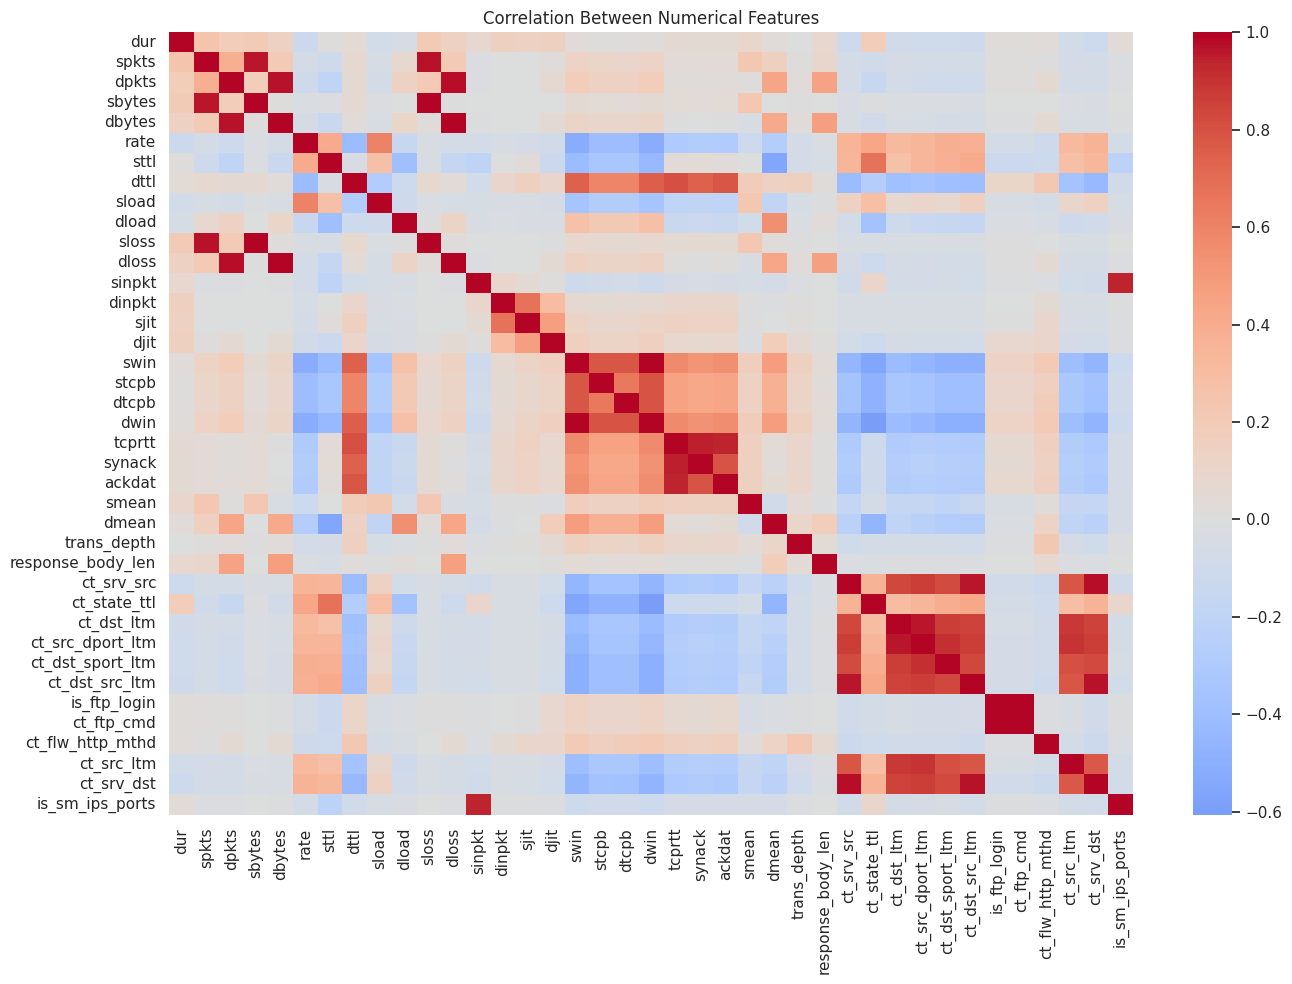

In [12]:
numeric_df = train_df.select_dtypes(include=np.number)

# Exclude identifier and target columns from feature correlation
corr_features = numeric_df.drop(
    columns=["id", "label"],
    errors="ignore"
)

plt.figure(figsize=(14, 10))
sns.heatmap(
    corr_features.corr(),
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

## EDA Summary and Key Insights

The exploratory data analysis of the UNSW-NB15 training dataset revealed several patterns relevant to network intrusion detection.

1. **Class distribution:** Attack records make up approximately 68.1% of the training data, while normal records make up 31.9%. Model evaluation should therefore include metrics beyond accuracy.

2. **Attack-category imbalance:** Some attack categories, particularly Worms, have far fewer records than common categories such as Generic. Per-class evaluation will be important for multiclass classification.

3. **Connection-state patterns:** Attack percentages vary across connection states. The `state` feature may contain useful predictive information, but rare categories must be interpreted cautiously.

4. **Protocol patterns:** Attack percentages differ between protocols in this dataset. Protocol may be useful for classification, but the observed associations should not be assumed to generalize to every network environment.

5. **Skewed numerical features:** Traffic-related variables such as byte counts and packet counts can have long-tailed distributions. Transformations and outlier handling should be evaluated rather than applied automatically.

6. **Feature correlation:** Correlated numerical features may contain overlapping information. Further analysis can guide feature selection and reduce unnecessary redundancy.

### Conclusion

EDA helps translate raw network traffic data into evidence-based modeling decisions. These findings provide a foundation for subsequent feature engineering, binary intrusion detection, multiclass attack classification, and model evaluation. The observations describe this dataset and should be validated on unseen data before being generalized to real-world network traffic.